# Rush 3 – Satisfaction client
## Partie A : exploration et facteurs de satisfaction

Ce notebook utilise **uniquement `train.csv`**. Il reproduit tous les chiffres des sections *Exploration* et *Facteurs* du rapport (sortie : `results_partA.json`). Graine fixée (`SEED = 42`) : deux exécutions donnent les mêmes résultats.

In [2]:
from pathlib import Path

# Chemin du fichier d'entraînement. Si le fichier n'est pas trouvé automatiquement, mettez ici son chemin complet,
# par ex. TRAIN_PATH = r"C:\Users\vous\Desktop\rush_3\train.csv"
TRAIN_PATH = None
if TRAIN_PATH is None:
    candidats = [Path(n) for n in ("data/raw/train.csv", "train.csv", "data/train.csv", "../data/raw/train.csv", "../train.csv", "../data/train.csv")]
    candidats += [p for p in Path(".").glob("*train*.csv")]
    TRAIN_PATH = next((p for p in candidats if p.exists()), None)
if TRAIN_PATH is None:
    raise FileNotFoundError(f"train.csv introuvable depuis {Path.cwd()}. Placez le fichier à côté du notebook ou renseignez TRAIN_PATH.")
print("Fichier utilisé :", Path(TRAIN_PATH).resolve())

Fichier utilisé : C:\Users\estev\Desktop\rush_3\data\raw\train.csv


In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
OUT = Path('.').resolve()
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
R = {}  # tous les resultats

SERVICES = [
    "Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
    "Gate location", "Food and drink", "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Inflight service", "Cleanliness",
]
FR = {
    "Inflight wifi service": "Wifi à bord", "Departure/Arrival time convenient": "Horaires pratiques",
    "Ease of Online booking": "Réservation en ligne", "Gate location": "Emplacement porte",
    "Food and drink": "Repas et boissons", "Online boarding": "Embarquement en ligne",
    "Seat comfort": "Confort du siège", "Inflight entertainment": "Divertissement à bord",
    "On-board service": "Service à bord", "Leg room service": "Espace jambes",
    "Baggage handling": "Gestion bagages", "Checkin service": "Enregistrement",
    "Inflight service": "Service en vol", "Cleanliness": "Propreté",
}
NAVY, ORANGE, GREY = "#1f3a5f", "#d9822b", "#8a8f98"

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


## 1. Nettoyage

- Suppression de la colonne d'index, contrôle des doublons.
- Les **0** des notes de service (= pas de réponse / non applicable) deviennent des valeurs manquantes.
- Retard à l'arrivée manquant : imputé par régression linéaire sur le retard au départ (corrélation 0,965).

In [4]:
# ------------------------------------------------------------------ 1. NETTOYAGE
raw = pd.read_csv(TRAIN_PATH)
R["n_lignes_brut"] = len(raw)
df = raw.drop(columns=[raw.columns[0]])           # colonne d'index inutile
R["doublons_id"] = int(df["id"].duplicated().sum())
R["doublons_lignes_hors_id"] = int(df.drop(columns="id").duplicated().sum())
df = df.drop_duplicates(subset="id").reset_index(drop=True)
df = df.rename(columns={"Customer Type": "Customer_Type", "Type of Travel": "Type_of_Travel"})
df["sat"] = (df["satisfaction"] == "satisfied").astype(int)
R["taux_satisfaits"] = round(df["sat"].mean() * 100, 1)

# zeros = non-reponse / non applicable -> valeur manquante
zeros = {FR[c]: int((df[c] == 0).sum()) for c in SERVICES}
R["zeros_par_service"] = zeros
R["part_zeros_par_service_pct"] = {FR[c]: round((df[c] == 0).mean() * 100, 1) for c in SERVICES}
R["lignes_avec_au_moins_un_zero"] = int((df[SERVICES] == 0).any(axis=1).sum())
R["part_lignes_avec_zero_pct"] = round((df[SERVICES] == 0).any(axis=1).mean() * 100, 1)
# le zero est-il lie a la satisfaction ? (informatif en soi)
R["taux_sat_si_zero_pct"] = {
    FR[c]: round(df.loc[df[c] == 0, "sat"].mean() * 100, 1) for c in SERVICES if (df[c] == 0).sum() > 50
}
df[SERVICES] = df[SERVICES].replace(0, np.nan)

# retards manquants
R["retard_arrivee_manquant"] = int(df["Arrival Delay in Minutes"].isna().sum())
R["corr_retard_dep_arr"] = round(df[["Departure Delay in Minutes", "Arrival Delay in Minutes"]].corr().iloc[0, 1], 3)
m = df["Arrival Delay in Minutes"].isna()
R["retard_manquant_dep_median"] = float(df.loc[m, "Departure Delay in Minutes"].median())
R["retard_manquant_taux_sat_pct"] = round(df.loc[m, "sat"].mean() * 100, 1)
R["retard_manquant_part_dep_zero_pct"] = round((df.loc[m, "Departure Delay in Minutes"] == 0).mean() * 100, 1)
# imputation : retard arrivee = retard depart + ecart median observe (regression simple)
ok = ~m
slope, intercept = np.polyfit(df.loc[ok, "Departure Delay in Minutes"], df.loc[ok, "Arrival Delay in Minutes"], 1)
R["imputation_retard_pente"] = round(float(slope), 3)
R["imputation_retard_intercept"] = round(float(intercept), 3)
df["arr_delay"] = df["Arrival Delay in Minutes"].fillna(
    (intercept + slope * df["Departure Delay in Minutes"]).clip(lower=0).round()
)
df["dep_delay"] = df["Departure Delay in Minutes"]
R["age_min"], R["age_max"], R["age_median"] = int(df.Age.min()), int(df.Age.max()), float(df.Age.median())
R["n_moins_16"] = int((df.Age < 16).sum())
R["n_moins_18"] = int((df.Age < 18).sum())
R["n_lignes_propres"] = len(df)


In [5]:
pd.DataFrame({"zéros (non-réponse)": R["zeros_par_service"], "% de zéros": R["part_zeros_par_service_pct"],
              "% satisfaits si zéro": pd.Series(R["taux_sat_si_zero_pct"])}).sort_values("zéros (non-réponse)", ascending=False)

,zéros (non-réponse),% de zéros,% satisfaits si zéro
Horaires pratiques,5300,5.1,47.5
Réservation en ligne,4487,4.3,66.4
Wifi à bord,3103,3.0,99.7
Embarquement en ligne,2428,2.3,55.6
Espace jambes,472,0.5,35.2
Repas et boissons,107,0.1,46.7
Divertissement à bord,14,0.0,NaN
Propreté,12,0.0,NaN
Service à bord,3,0.0,NaN
Service en vol,3,0.0,NaN


## 2. Exploration

Taux de passagers satisfaits selon la classe, le type de voyage, la fidélité, le genre, l'âge, les retards et la distance. On vérifie aussi si les écarts viennent d'un effet de composition (ex. l'âge ou la distance à classe et motif constants).

In [6]:
# ------------------------------------------------------------------ 2. EXPLORATION
def rate(col, order=None):
    g = df.groupby(col, observed=True)["sat"].agg(["mean", "size"])
    g["mean"] = (g["mean"] * 100).round(1)
    if order:
        g = g.loc[order]
    return {str(k): {"taux_pct": float(v["mean"]), "n": int(v["size"])} for k, v in g.iterrows()}

df["tranche_age"] = pd.cut(df.Age, [0, 17, 25, 35, 45, 55, 65, 120],
                           labels=["<18", "18-25", "26-35", "36-45", "46-55", "56-65", ">65"])
df["tranche_retard"] = pd.cut(df.arr_delay, [-1, 0, 15, 60, 120, 5000],
                              labels=["0 min", "1-15", "16-60", "61-120", ">120"])
df["tranche_dist"] = pd.cut(df["Flight Distance"], [0, 500, 1000, 2000, 3000, 10000],
                            labels=["<500", "500-1000", "1000-2000", "2000-3000", ">3000"])
for c, key in [("Class", "classe"), ("Type_of_Travel", "type_voyage"), ("Customer_Type", "fidelite"),
               ("Gender", "genre"), ("tranche_age", "age"), ("tranche_retard", "retard_arrivee"),
               ("tranche_dist", "distance")]:
    R[f"taux_par_{key}"] = rate(c)
R["taux_classe_x_voyage"] = {
    f"{a} | {b}": {"taux_pct": round(g.sat.mean() * 100, 1), "n": int(len(g))}
    for (a, b), g in df.groupby(["Class", "Type_of_Travel"])
}
R["taux_fidelite_x_voyage"] = {
    f"{a} | {b}": {"taux_pct": round(g.sat.mean() * 100, 1), "n": int(len(g))}
    for (a, b), g in df.groupby(["Customer_Type", "Type_of_Travel"])
}
R["repartition_classe_pct"] = (df.Class.value_counts(normalize=True) * 100).round(1).to_dict()
R["repartition_voyage_pct"] = (df.Type_of_Travel.value_counts(normalize=True) * 100).round(1).to_dict()
R["repartition_fidelite_pct"] = (df.Customer_Type.value_counts(normalize=True) * 100).round(1).to_dict()
R["part_retard_arrivee_nul_pct"] = round((df.arr_delay == 0).mean() * 100, 1)
R["retard_arrivee_median_si_positif"] = float(df.loc[df.arr_delay > 0, "arr_delay"].median())
R["retard_arrivee_p95"] = float(df.arr_delay.quantile(0.95))
R["retard_arrivee_max"] = float(df.arr_delay.max())
R["corr_spearman_retard_sat"] = round(df[["arr_delay", "sat"]].corr(method="spearman").iloc[0, 1], 3)
R["corr_spearman_age_sat"] = round(df[["Age", "sat"]].corr(method="spearman").iloc[0, 1], 3)
R["corr_spearman_distance_sat"] = round(df[["Flight Distance", "sat"]].corr(method="spearman").iloc[0, 1], 3)
# effet du retard a profil constant (classe x voyage)
base = df.groupby(["Class", "Type_of_Travel"])["sat"].transform("mean")
R["effet_retard_a_profil_constant"] = {
    str(k): round(float((g.sat.mean() - base[g.index].mean()) * 100), 1)
    for k, g in df.groupby("tranche_retard", observed=True)
}
# part de pax avec classe Business par tranche d'age (confusion possible)
R["part_business_par_age_pct"] = (df.groupby("tranche_age", observed=True)["Class"].apply(lambda s: (s == "Business").mean() * 100)).round(1).to_dict()
R["part_voyage_pro_par_age_pct"] = (df.groupby("tranche_age", observed=True)["Type_of_Travel"].apply(lambda s: (s == "Business travel").mean() * 100)).round(1).to_dict()


In [7]:
pd.concat({k.replace("taux_par_", ""): pd.DataFrame(R[k]).T for k in
           ["taux_par_classe", "taux_par_type_voyage", "taux_par_fidelite", "taux_par_genre", "taux_par_age",
            "taux_par_retard_arrivee", "taux_par_distance"]})

taux_pct        n
classe         Business               69.4  49665.0
               Eco                    18.6  46745.0
               Eco Plus               24.6   7494.0
type_voyage    Business travel        58.3  71655.0
               Personal Travel        10.2  32249.0
fidelite       Loyal Customer         47.7  84923.0
               disloyal Customer      23.7  18981.0
genre          Female                 42.7  52727.0
               Male                   43.9  51177.0
age            <18                    16.4   7931.0
               18-25                  34.4  14682.0
               26-35                  37.5  18848.0
               36-45                  52.0  24548.0
               46-55                  57.7  20949.0
               56-65                  46.4  12940.0
               >65                    18.4   4006.0
retard_arrivee 0 min                  47.3  58159.0
               1-15                   41.3  21974.0
               16-60                  35.5  16376.0
               61-120                 35.2   4749.0
               >120                   36.7   2646.0
distance       <500                   33.3  32321.0
               500-1000               32.5  27744.0
               1000-2000              46.1  22426.0
               2000-3000              64.7  13148.0
               >3000                  77.4   8265.0

### Figure 1 – taux de satisfaits par profil

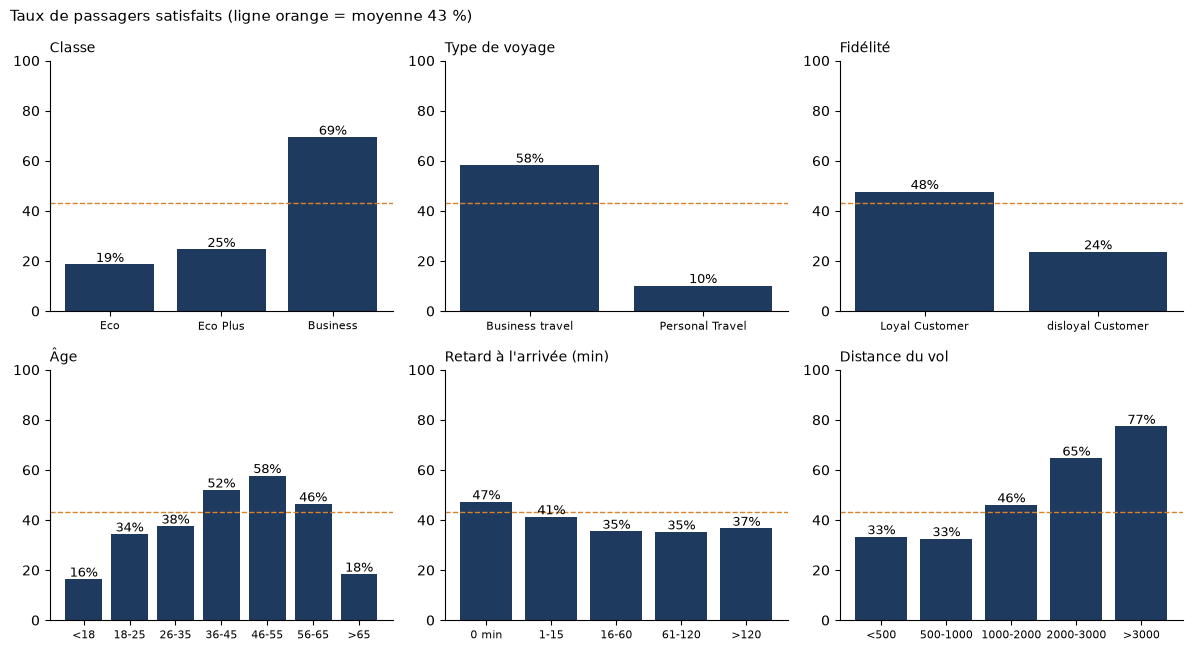

In [33]:
# --- Figures exploration
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6))
def bar(ax, col, title, order=None):
    g = df.groupby(col, observed=True)["sat"].mean() * 100
    if order: g = g.loc[order]
    b = ax.bar(g.index.astype(str), g.values, color=NAVY)
    ax.axhline(df.sat.mean() * 100, color=ORANGE, ls="--", lw=1)
    for r_, v in zip(b, g.values): ax.text(r_.get_x() + r_.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_ylim(0, 100); ax.set_title(title, fontsize=10, loc="left"); ax.tick_params(axis="x", labelsize=8)
bar(axes[0, 0], "Class", "Classe", ["Eco", "Eco Plus", "Business"])
bar(axes[0, 1], "Type_of_Travel", "Type de voyage")
bar(axes[0, 2], "Customer_Type", "Fidélité")
bar(axes[1, 0], "tranche_age", "Âge")
bar(axes[1, 1], "tranche_retard", "Retard à l'arrivée (min)")
bar(axes[1, 2], "tranche_dist", "Distance du vol")
fig.suptitle(f"Taux de passagers satisfaits (ligne orange = moyenne {df.sat.mean()*100:.0f} %)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "fig1_taux_satisfaction.png", dpi=170); plt.show()


### Figure 2 – classe × type de voyage

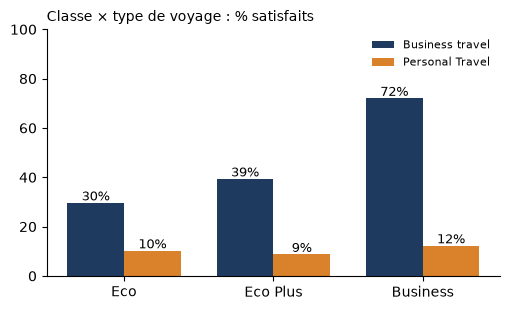

In [9]:
# classe x voyage
pv = df.pivot_table(index="Class", columns="Type_of_Travel", values="sat", aggfunc="mean").loc[["Eco", "Eco Plus", "Business"]] * 100
fig, ax = plt.subplots(figsize=(5.2, 3.2))
w = 0.38; x = np.arange(3)
for i, (c, colr) in enumerate(zip(pv.columns, [NAVY, ORANGE])):
    b = ax.bar(x + (i - .5) * w, pv[c], w, label=c, color=colr)
    for r_, v in zip(b, pv[c]): ax.text(r_.get_x() + r_.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(pv.index); ax.set_ylim(0, 100); ax.legend(frameon=False, fontsize=8)
ax.set_title("Classe × type de voyage : % satisfaits", fontsize=10, loc="left")
fig.tight_layout(); fig.savefig(FIG / "fig2_classe_x_voyage.png", dpi=170); plt.show()


In [10]:
pd.DataFrame(R["taux_classe_x_voyage"]).T

,taux_pct,n
Business | Business travel,72.0,47508.0
Business | Personal Travel,12.2,2157.0
Eco | Business travel,29.6,20257.0
Eco | Personal Travel,10.2,26488.0
Eco Plus | Business travel,39.3,3890.0
Eco Plus | Personal Travel,8.7,3604.0


## 3. Facteurs de satisfaction

Trois lectures complémentaires des 14 notes de service : corrélation de Spearman, régression logistique, importance par permutation. Le découpage 75/25 utilisé pour évaluer les modèles est **interne au train** ; le fichier test n'est jamais ouvert.

In [11]:
# ------------------------------------------------------------------ 3. FACTEURS


In [12]:
# 3a. correlations (Spearman, paires completes) notes <-> satisfaction
corr = {FR[c]: round(float(df[[c, "sat"]].dropna().corr(method="spearman").iloc[0, 1]), 3) for c in SERVICES}
R["corr_spearman_note_sat"] = dict(sorted(corr.items(), key=lambda kv: -kv[1]))
# ecart de taux de satisfaction entre notes 4-5 et notes 1-2
gap = {}
for c in SERVICES:
    s = df[[c, "sat"]].dropna()
    gap[FR[c]] = round(float((s.loc[s[c] >= 4, "sat"].mean() - s.loc[s[c] <= 2, "sat"].mean()) * 100), 1)
R["ecart_taux_sat_notes_4-5_vs_1-2_pts"] = dict(sorted(gap.items(), key=lambda kv: -kv[1]))
R["note_moyenne"] = {FR[c]: round(float(df[c].mean()), 2) for c in SERVICES}
R["part_notes_1_2_pct"] = {FR[c]: round(float((df[c] <= 2).sum() / df[c].notna().sum() * 100), 1) for c in SERVICES}


In [13]:
pd.DataFrame({"corrélation Spearman": R["corr_spearman_note_sat"], "écart de taux notes 4-5 vs 1-2 (pts)": R["ecart_taux_sat_notes_4-5_vs_1-2_pts"],
              "note moyenne": R["note_moyenne"], "% notes 1-2": R["part_notes_1_2_pct"]}).sort_values("corrélation Spearman", ascending=False)

,corrélation Spearman,écart de taux notes 4-5 vs 1-2 (pts),note moyenne,% notes 1-2
Embarquement en ligne,0.590,59.9,3.33,27.8
Divertissement à bord,0.399,44.6,3.36,29.0
Wifi à bord,0.372,46.3,2.81,43.3
Confort du siège,0.362,37.8,3.44,26.0
Service à bord,0.328,35.5,3.38,25.6
Espace jambes,0.320,34.7,3.37,28.9
Propreté,0.303,36.3,3.29,28.3
Gestion bagages,0.269,24.0,3.63,18.1
Service en vol,0.265,23.6,3.64,17.8
Réservation en ligne,0.234,28.3,2.88,41.8


In [14]:
# 3b. regression logistique sur les notes
# NaN -> note neutre (3) + indicateur "non repondu" pour les services concernes (>1 % de NaN)
X = df[SERVICES].copy()
ind_cols = []
for c in SERVICES:
    if X[c].isna().mean() > 0.01:
        X[f"{c}__NR"] = X[c].isna().astype(int); ind_cols.append(f"{c}__NR")
X[SERVICES] = X[SERVICES].fillna(3)
y = df["sat"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)  # split INTERNE au train
sc = StandardScaler().fit(Xtr[SERVICES])
def prep(Z):
    Z = Z.copy(); Z[SERVICES] = sc.transform(Z[SERVICES]); return Z
lr = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED).fit(prep(Xtr), ytr)
from sklearn.metrics import roc_auc_score
R["auc_logreg_notes_holdout_interne"] = round(float(roc_auc_score(yte, lr.predict_proba(prep(Xte))[:, 1])), 3)
coef = pd.Series(lr.coef_[0], index=X.columns)
R["logreg_notes_coef_standardises"] = {FR[c]: round(float(coef[c]), 3) for c in coef.sort_values(ascending=False).index if c in SERVICES}
R["logreg_notes_odds_ratio_par_ecart_type"] = {k: round(float(np.exp(v)), 2) for k, v in R["logreg_notes_coef_standardises"].items()}

# odds-ratio par +1 point de note (echelle brute) avec IC bootstrap-free via statsmodels
import statsmodels.api as sm
Xs = sm.add_constant(X.astype(float))
res = sm.Logit(y, Xs).fit(disp=0)
ci = res.conf_int()
R["logreg_notes_OR_par_point"] = {
    FR[c]: {"OR": round(float(np.exp(res.params[c])), 2), "IC95": [round(float(np.exp(ci.loc[c, 0])), 2), round(float(np.exp(ci.loc[c, 1])), 2)],
            "p": float(res.pvalues[c])} for c in SERVICES
}


In [15]:
pd.DataFrame({k: {"odds ratio / point": v["OR"], "IC95 bas": v["IC95"][0], "IC95 haut": v["IC95"][1]} for k, v in R["logreg_notes_OR_par_point"].items()}).T.sort_values("odds ratio / point", ascending=False)

,odds ratio / point,IC95 bas,IC95 haut
Embarquement en ligne,2.78,2.72,2.84
Wifi à bord,1.97,1.92,2.02
Espace jambes,1.47,1.44,1.49
Service à bord,1.42,1.39,1.45
Divertissement à bord,1.40,1.36,1.44
Enregistrement,1.30,1.28,1.32
Réservation en ligne,1.22,1.19,1.25
Confort du siège,1.19,1.17,1.22
Gestion bagages,1.09,1.07,1.12
Propreté,1.06,1.03,1.08


In [16]:
# 3c. importance par permutation (gradient boosting sur notes, evalue sur hold-out interne)
gb = HistGradientBoostingClassifier(random_state=SEED, max_iter=200).fit(Xtr, ytr)
R["auc_gb_notes_holdout_interne"] = round(float(roc_auc_score(yte, gb.predict_proba(Xte)[:, 1])), 3)
pi = permutation_importance(gb, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X.columns)
R["importance_permutation_auc_perdue"] = {FR[c]: round(float(imp[c]), 4) for c in imp.loc[SERVICES].sort_values(ascending=False).index}


In [17]:
pd.Series(R["importance_permutation_auc_perdue"], name="AUC perdue (permutation)").to_frame()

,AUC perdue (permutation)
Wifi à bord,0.1591
Emplacement porte,0.0356
Embarquement en ligne,0.0313
Horaires pratiques,0.0165
Espace jambes,0.0092
Divertissement à bord,0.0063
Propreté,0.0059
Enregistrement,0.0051
Réservation en ligne,0.0051
Service en vol,0.0042


In [18]:
# 3d. avec controle du contexte (classe, voyage, fidelite, age, distance, retards)
ctx = pd.get_dummies(df[["Class", "Type_of_Travel", "Customer_Type", "Gender"]], drop_first=True).astype(float)
ctx["Age"] = df.Age; ctx["Dist"] = df["Flight Distance"]; ctx["dep_delay"] = df.dep_delay; ctx["arr_delay"] = df.arr_delay
Xc = pd.concat([X.astype(float), ctx], axis=1)
Xc_tr, Xc_te = Xc.loc[Xtr.index], Xc.loc[Xte.index]
sc2 = StandardScaler().fit(Xc_tr)
lr2 = LogisticRegression(max_iter=3000, random_state=SEED).fit(sc2.transform(Xc_tr), ytr)
R["auc_logreg_notes_plus_contexte"] = round(float(roc_auc_score(yte, lr2.predict_proba(sc2.transform(Xc_te))[:, 1])), 3)
coef2 = pd.Series(lr2.coef_[0], index=Xc.columns)
R["coef_std_notes_avec_controle_contexte"] = {FR[c]: round(float(coef2[c]), 3) for c in coef.loc[SERVICES].sort_values(ascending=False).index}
R["coef_std_contexte"] = {c: round(float(coef2[c]), 3) for c in ctx.columns}
gb2 = HistGradientBoostingClassifier(random_state=SEED, max_iter=200).fit(Xc_tr, ytr)
R["auc_gb_notes_plus_contexte"] = round(float(roc_auc_score(yte, gb2.predict_proba(Xc_te)[:, 1])), 3)
# AUC du contexte seul
sc3 = StandardScaler().fit(ctx.loc[Xtr.index])
lr3 = LogisticRegression(max_iter=3000, random_state=SEED).fit(sc3.transform(ctx.loc[Xtr.index]), ytr)
R["auc_contexte_seul"] = round(float(roc_auc_score(yte, lr3.predict_proba(sc3.transform(ctx.loc[Xte.index]))[:, 1])), 3)


In [19]:
pd.DataFrame({"notes seules": R["logreg_notes_coef_standardises"], "notes + profil": R["coef_std_notes_avec_controle_contexte"]}).sort_values("notes seules", ascending=False)

,notes seules,notes + profil
Embarquement en ligne,1.283,1.158
Wifi à bord,0.841,1.043
Espace jambes,0.495,0.397
Service à bord,0.446,0.446
Divertissement à bord,0.444,0.106
Enregistrement,0.333,0.448
Réservation en ligne,0.267,0.495
Confort du siège,0.243,0.055
Gestion bagages,0.113,0.203
Propreté,0.062,0.310


In [20]:
print({k: v for k, v in R.items() if k.startswith("auc_")})

{'auc_logreg_notes_holdout_interne': 0.924, 'auc_gb_notes_holdout_interne': 0.99, 'auc_logreg_notes_plus_contexte': 0.964, 'auc_gb_notes_plus_contexte': 0.995, 'auc_contexte_seul': 0.848}


In [21]:
# 3e. par segment (le levier depend du segment)
seg = {}
for name, mask in [("Voyage professionnel", df.Type_of_Travel == "Business travel"),
                   ("Voyage personnel", df.Type_of_Travel == "Personal Travel"),
                   ("Business (classe)", df.Class == "Business"), ("Eco (classe)", df.Class == "Eco")]:
    Xs_, ys_ = X.loc[mask, SERVICES], y[mask]
    s_ = StandardScaler().fit(Xs_)
    m_ = LogisticRegression(max_iter=2000, random_state=SEED).fit(s_.transform(Xs_), ys_)
    c_ = pd.Series(m_.coef_[0], index=SERVICES).sort_values(ascending=False)
    seg[name] = {"n": int(mask.sum()), "taux_sat_pct": round(float(ys_.mean() * 100), 1),
                 "top5": {FR[k]: round(float(v), 2) for k, v in c_.head(5).items()}}
R["facteurs_par_segment_coef_std"] = seg


In [22]:
pd.DataFrame({k: {"n": v["n"], "% satisfaits": v["taux_sat_pct"], **{f"top{i+1}": f"{a} ({b})" for i, (a, b) in enumerate(v["top5"].items())}} for k, v in R["facteurs_par_segment_coef_std"].items()}).T

,n,% satisfaits,top1,top2,top3,top4,top5
Voyage professionnel,71655,58.3,Embarquement en ligne (1.26),Service à bord (0.54),Divertissement à bord (0.46),Enregistrement (0.46),Wifi à bord (0.44)
Voyage personnel,32249,10.2,Wifi à bord (2.96),Confort du siège (0.05),Propreté (0.03),Gestion bagages (0.03),Service en vol (0.02)
Business (classe),49665,69.4,Embarquement en ligne (1.04),Espace jambes (0.56),Wifi à bord (0.49),Service à bord (0.46),Enregistrement (0.39)
Eco (classe),46745,18.6,Wifi à bord (2.77),Divertissement à bord (0.24),Enregistrement (0.16),Service à bord (0.12),Emplacement porte (0.08)


### Figures 3 et 4 – poids des notes (avant / après contrôle du profil)

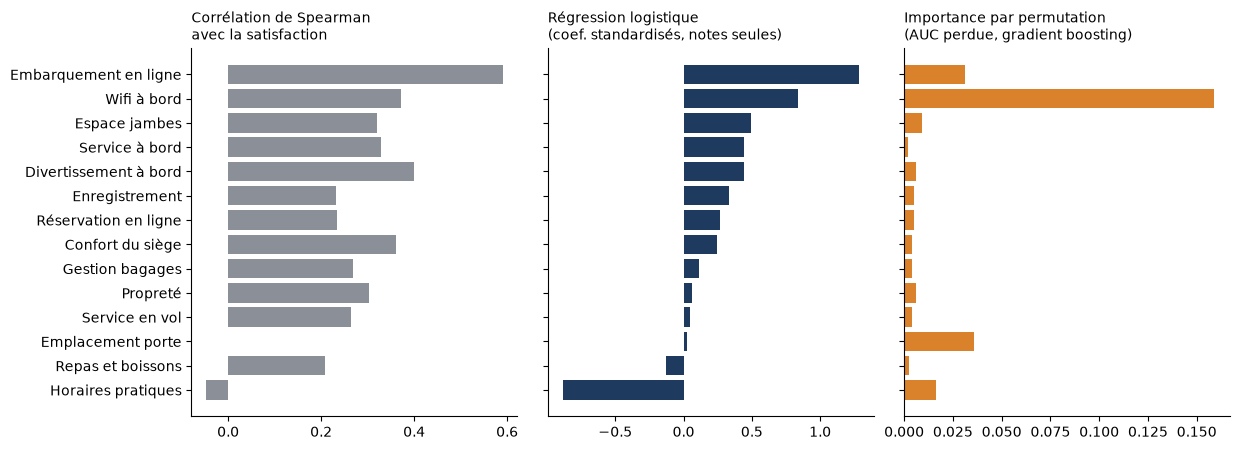

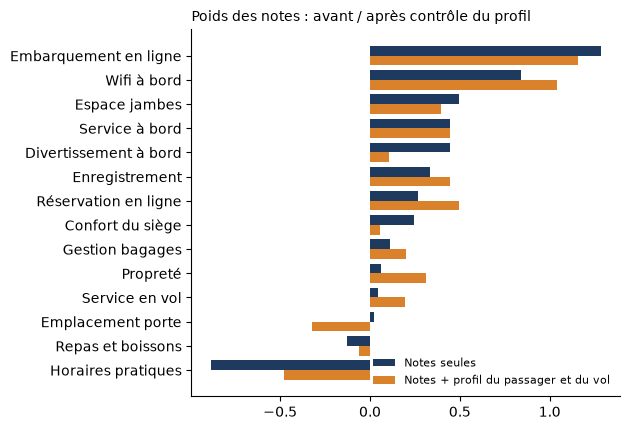

In [23]:
# --- Figures facteurs
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.6), sharey=False)
order = list(R["logreg_notes_coef_standardises"].keys())[::-1]
ax = axes[0]; ax.barh(order, [R["corr_spearman_note_sat"][k] for k in order], color=GREY)
ax.set_title("Corrélation de Spearman\navec la satisfaction", fontsize=10, loc="left")
ax = axes[1]; ax.barh(order, [R["logreg_notes_coef_standardises"][k] for k in order], color=NAVY)
ax.set_title("Régression logistique\n(coef. standardisés, notes seules)", fontsize=10, loc="left"); ax.set_yticklabels([])
ax = axes[2]; ax.barh(order, [R["importance_permutation_auc_perdue"][k] for k in order], color=ORANGE)
ax.set_title("Importance par permutation\n(AUC perdue, gradient boosting)", fontsize=10, loc="left"); ax.set_yticklabels([])
fig.tight_layout(); fig.savefig(FIG / "fig3_facteurs.png", dpi=170); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 4.4))
o2 = order
ax.barh(np.arange(len(o2)) + .2, [R["logreg_notes_coef_standardises"][k] for k in o2], .4, color=NAVY, label="Notes seules")
ax.barh(np.arange(len(o2)) - .2, [R["coef_std_notes_avec_controle_contexte"][k] for k in o2], .4, color=ORANGE, label="Notes + profil du passager et du vol")
ax.set_yticks(np.arange(len(o2))); ax.set_yticklabels(o2); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Poids des notes : avant / après contrôle du profil", fontsize=10, loc="left")
fig.tight_layout(); fig.savefig(FIG / "fig4_facteurs_controle.png", dpi=170); plt.show()


## 4. Vérifications complémentaires

Taux par note (effets de seuil), effet de suppression de « Horaires pratiques », effet propre de l'âge et de la distance, retard par segment.

In [24]:
# ------------------------------------------------------------------ 4. VERIFICATIONS COMPLEMENTAIRES


In [25]:
# 4a. taux de satisfaction par note (non-linearite / effet de seuil), NaN = "non repondu"
par_note = {}
for c in SERVICES:
    g = df.groupby(df[c].fillna(0).astype(int))["sat"].mean() * 100
    par_note[FR[c]] = {("NR" if k == 0 else str(k)): round(float(v), 1) for k, v in g.items()}
R["taux_sat_par_note"] = par_note


In [26]:
# 4b. "Horaires pratiques" : signe inverse en multivarie = effet de suppression ?
def std_coef(cols):
    Z = X[cols]; Z = StandardScaler().fit_transform(Z)
    m_ = LogisticRegression(max_iter=2000, random_state=SEED).fit(Z, y)
    return {FR[c] if c in FR else c: round(float(v), 3) for c, v in zip(cols, m_.coef_[0])}
h, w_, b_ = "Departure/Arrival time convenient", "Inflight wifi service", "Ease of Online booking"
R["suppression_horaires_seul"] = std_coef([h])
R["suppression_horaires_wifi"] = std_coef([h, w_])
R["suppression_horaires_wifi_resa"] = std_coef([h, w_, b_])
R["corr_spearman_horaires_wifi_resa"] = {
    "horaires-wifi": round(float(df[[h, w_]].dropna().corr(method="spearman").iloc[0, 1]), 2),
    "horaires-resa": round(float(df[[h, b_]].dropna().corr(method="spearman").iloc[0, 1]), 2),
    "wifi-resa": round(float(df[[w_, b_]].dropna().corr(method="spearman").iloc[0, 1]), 2),
}


In [27]:
pd.DataFrame({"horaires seul": R["suppression_horaires_seul"], "+ wifi": R["suppression_horaires_wifi"], "+ wifi + réservation": R["suppression_horaires_wifi_resa"]}).T

,Horaires pratiques,Wifi à bord,Réservation en ligne
horaires seul,-0.098,NaN,NaN
+ wifi,-0.626,1.175,NaN
+ wifi + réservation,-0.687,1.069,0.196


In [28]:
# 4c. age et distance : effet propre ou effet de composition (classe / motif) ?
P1 = (df.Class == "Business") & (df.Type_of_Travel == "Business travel")
P2 = (df.Class == "Eco") & (df.Type_of_Travel == "Personal Travel")
R["age_dans_Business_x_voyagepro"] = {k: round(float(v * 100), 1) for k, v in df[P1].groupby("tranche_age", observed=True)["sat"].mean().items()}
R["age_dans_Eco_x_voyageperso"] = {k: round(float(v * 100), 1) for k, v in df[P2].groupby("tranche_age", observed=True)["sat"].mean().items()}
R["part_business_par_distance_pct"] = (df.groupby("tranche_dist", observed=True)["Class"].apply(lambda s: (s == "Business").mean() * 100)).round(1).to_dict()
R["distance_dans_Business_x_voyagepro"] = {k: round(float(v * 100), 1) for k, v in df[P1].groupby("tranche_dist", observed=True)["sat"].mean().items()}
R["distance_dans_Eco_x_voyageperso"] = {k: round(float(v * 100), 1) for k, v in df[P2].groupby("tranche_dist", observed=True)["sat"].mean().items()}
R["retard_dans_Business_x_voyagepro"] = {k: round(float(v * 100), 1) for k, v in df[P1].groupby("tranche_retard", observed=True)["sat"].mean().items()}
R["retard_dans_Eco_x_voyageperso"] = {k: round(float(v * 100), 1) for k, v in df[P2].groupby("tranche_retard", observed=True)["sat"].mean().items()}
R["enfants_moins_18_Business_x_voyagepro_taux_pct"] = round(float(df[P1 & (df.Age < 18)].sat.mean() * 100), 1)
R["n_Business_x_voyagepro"] = int(P1.sum()); R["n_Eco_x_voyageperso"] = int(P2.sum())


In [29]:
pd.DataFrame({"Business × voyage pro": R["age_dans_Business_x_voyagepro"], "Eco × voyage perso": R["age_dans_Eco_x_voyageperso"]})

,Business × voyage pro,Eco × voyage perso
<18,49.4,10.7
18-25,66.3,10.0
26-35,60.5,10.5
36-45,73.1,9.9
46-55,82.3,10.1
56-65,79.0,10.3
>65,38.0,9.3


In [30]:
# 4d. taux de satisfaction selon le nombre de services notes >= 4 (resume "experience a bord")
df["nb_notes_4plus"] = (df[SERVICES] >= 4).sum(axis=1)
R["taux_sat_par_nb_notes_4plus"] = {
    str(k): round(float(v * 100), 1)
    for k, v in df.groupby(pd.cut(df.nb_notes_4plus, [-1, 2, 5, 8, 11, 14]), observed=True)["sat"].mean().items()}


### Figure 5 – taux de satisfaits selon la note donnée

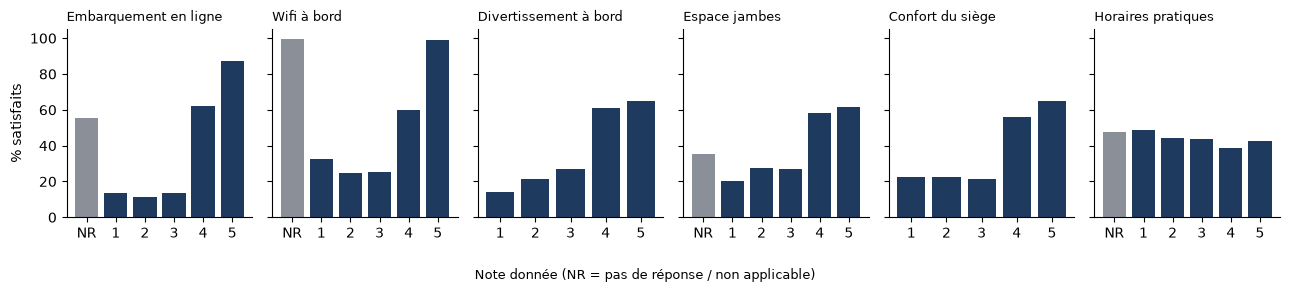

In [31]:
# Figure : taux de satisfaction par note pour les services cles
key = ["Online boarding", "Inflight wifi service", "Inflight entertainment", "Leg room service", "Seat comfort", "Departure/Arrival time convenient"]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.9), sharey=True)
for ax, c in zip(axes, key):
    d_ = par_note[FR[c]]; ks = ["NR", "1", "2", "3", "4", "5"]; ks = [k for k in ks if k in d_]
    if zeros[FR[c]] < 50 and "NR" in ks: ks.remove("NR")  # NR trop rare pour etre affiche
    ax.bar(ks, [d_[k] for k in ks], color=[GREY if k == "NR" else NAVY for k in ks])
    ax.set_title(FR[c], fontsize=9, loc="left"); ax.set_ylim(0, 105)
axes[0].set_ylabel("% satisfaits"); fig.supxlabel("Note donnée (NR = pas de réponse / non applicable)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "fig5_taux_par_note.png", dpi=170); plt.show()


## 5. Export

Tous les chiffres cités dans le rapport sont écrits dans `results_partA.json`.

In [32]:
# ------------------------------------------------------------------ EXPORT
with open(OUT / "results_partA.json", "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2)
df.drop(columns=["tranche_age", "tranche_retard", "tranche_dist"]).to_csv((Path("data/clean") if Path("data/clean").is_dir() else OUT) / "train_clean_partA.csv", index=False)
print('Export termine : results_partA.json, train_clean_partA.csv, figures/')


Export termine : results_partA.json, train_clean_partA.csv, figures/
